In [96]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import matplotlib
import matplotlib.pyplot as plt
import sigpy as sp
import pandas as pd
import sigpy.plot as pl
import numpy as np
import os
import sys
from pathlib import Path
import jax as jx
import time
import h5py


sys.path.insert(0,'/Users/ayman/Desktop/MSc Project Local/MSc-Project-ZTE')
import aymansigmri as asm

sys.path.insert(0, "/Users/ayman/Documents/GitHub/riesling/python")

import riesling as rlp


riesling_bin = Path.home() / "Documents" / "github" / "riesling" / "build" / "cxx" / "riesling"
os.environ["PATH"] += os.pathsep + str(riesling_bin)

save_dir = "/Users/ayman/Desktop/LowRank/Data Saved"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data

In [97]:
zte = '/Users/ayman/Desktop/LowRank/Data Saved/Brain/zte'
coorhires_zte = rlp.io.read_trajectory(f'{zte}.h5')
coorhires_zte = np.asarray(coorhires_zte)
kspacehires_zte = rlp.io.read_data(f'{zte}.h5')
kspacehires_zte = np.asarray(kspacehires_zte)
kspacehires_zte = kspacehires_zte[0, 0] 
kspacehires_zte = np.moveaxis(kspacehires_zte, -1, 0)

In [98]:
def h5tonum_interled(file, showshape=False, load_traj=True, stripdims=True):
    with h5py.File(file) as f:
        d = f['data'][:]
        if stripdims:
            d = d[0, 0]
        d = np.moveaxis(d,-1, 0)
        if load_traj:
            traj = f['trajectory'][:]
            if showshape:
                print(d.shape)
                print(traj.shape)
            return d, traj
        else:
            if showshape:
                print(d.shape)
            return d


In [99]:
zte_ksp, traj = asm.h5tonum_interleaved(f'{zte}.h5', showshape=True)

(18, 65278, 248)
(65278, 248, 3)


## Reshaping and Removing

In [ ]:
data1 = zte_ksp[0]
data1.shape[0]

num_segments = data1.shape[0]/257

segments = np.split(data1, num_segments)

len(segments)

segments = segments[:-4]

250

In [ ]:
segment1 = segments[0]
## GOAL: Remove first spoke in a segment
segment_cleaned = segment1[1:]

(257, 248)

In [100]:
cleaned_data = []
for coil in zte_ksp:
    if coil.shape[0] % 257 != 0:
        raise ValueError(f'{coil.shape[0]} spokes not divisible by 257')
    num_segments = coil.shape[0] // 257
    segments = np.split(coil, num_segments)[:-4] #split into segments
    cleaned_data.append(np.concatenate([s[1:] for s in segments], axis=0))

cleaned_data = np.stack(cleaned_data)

In [101]:
num_segments_traj = traj.shape[0] // 257
segments_traj = np.split(traj, num_segments)[:-4]
cleaned_trajectory = np.concatenate([st[1:] for st in segments_traj], axis=0)

cleaned_trajectory.shape

(64000, 248, 3)

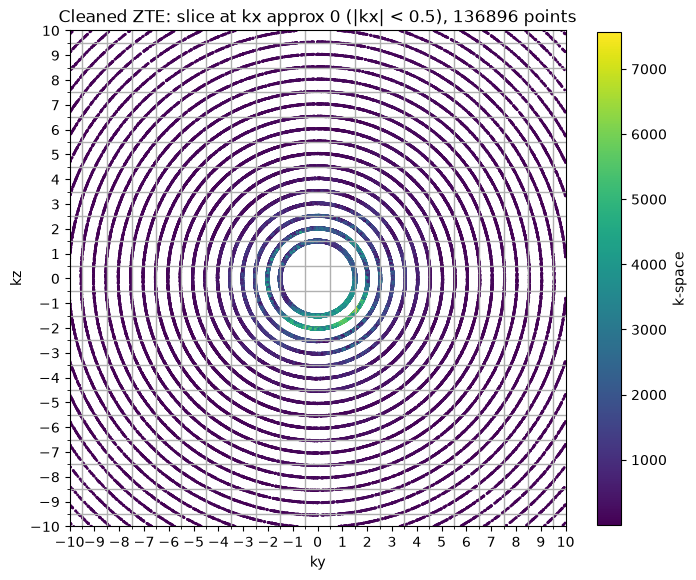

In [ ]:
clean_coords = cleaned_trajectory.reshape(-1, 3)
clean_mag = np.abs(cleaned_data[0]).reshape(-1)

fig, ax1 = plt.subplots(figsize=(8, 8))

tol = 0.5  
mask_clean = (np.abs(clean_coords[:, 0]) < tol) \
           & (np.abs(clean_coords[:, 1]) < 10) \
           & (np.abs(clean_coords[:, 2]) < 10)

im1 = ax1.scatter(
    clean_coords[mask_clean, 1], clean_coords[mask_clean, 2],
    c=clean_mag[mask_clean],
    s=1
)
ax1.set_title(f'Cleaned ZTE: slice at kx approx 0 (|kx| < {tol}), {mask_clean.sum()} points')
ax1.set_xlabel('ky')
ax1.set_ylabel('kz')
ax1.set_aspect('equal')
ax1.xaxis.set_major_locator(plt.MultipleLocator(1))
ax1.yaxis.set_major_locator(plt.MultipleLocator(1))
ax1.grid(visible=True, which='minor', linewidth=1)
ax1.xaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax1.yaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
fig.colorbar(im1, ax=ax1, label='k-space', shrink=0.8)

plt.show()

## Get this back to h5 so I can fft